# A checked federated run

Four hospitals want a shared risk model and can't pool their records. This notebook trains one with fedtally, then shows the three things that make it different from a normal federated run:

1. The aggregator never sees an update, only noise.
2. Anyone can check the result from a small log, with no access to the data or the aggregator.
3. Each hospital decides for itself what it will take part in.

The data is synthetic, and everything runs on this machine over real TLS on loopback.

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import fedtally as ft

workdir = tempfile.TemporaryDirectory()
root = Path(workdir.name)

## The hospitals

Each hospital has a different number of patients and a different mix of them, so no single site's data looks like the whole population.

In [2]:
FEATURES = 12
rng = np.random.default_rng(7)
true_weights = rng.normal(size=FEATURES)


def patients(n, shift, rng):
    x = rng.normal(loc=shift, size=(n, FEATURES)).astype(np.float32)
    p = 1 / (1 + np.exp(-(x @ true_weights - shift.sum() * 0.5)))
    return x, (rng.random(n) < p).astype(np.float32)


sizes = [400, 900, 300, 1400]
shifts = [rng.normal(scale=0.8, size=FEATURES) for _ in sizes]
hospitals = [patients(n, s, rng) for n, s in zip(sizes, shifts)]
test_x, test_y = map(np.concatenate, zip(*[patients(1000, s, rng) for s in shifts]))


def accuracy(params):
    logits = test_x @ np.asarray(params["w"]) + float(np.asarray(params["b"])[0])
    return float(((logits > 0) == (test_y > 0.5)).mean())


def fit(params, x, y, epochs=20, lr=0.1):
    w, b = np.array(params["w"]), np.array(params["b"])
    for _ in range(epochs):
        p = 1 / (1 + np.exp(-(x @ w + b[0])))
        w -= lr * (x.T @ (p - y)) / len(y)
        b -= lr * np.array([(p - y).mean()], dtype=np.float32)
    return {"w": w, "b": b}


start = {"w": np.zeros(FEATURES, np.float32), "b": np.zeros(1, np.float32)}
ROUNDS = 12

everyone = fit(start, *map(np.concatenate, zip(*hospitals)), epochs=20 * ROUNDS)
alone = [accuracy(fit(start, x, y, epochs=20 * ROUNDS)) for x, y in hospitals]
print(f"all data in one place: {accuracy(everyone):.3f}")
print(f"each hospital alone:   {np.mean(alone):.3f} on average")

all data in one place: 0.814
each hospital alone:   0.736 on average


## Train together

`train` runs at each hospital and is ordinary Python. It gets the current model and returns the model after local training, plus a weight. Everything else happens in Rust: masking, signing, transfer and summing.

`helpers=1` means secrecy is split between the aggregator and one helper. They would have to collude to read an update.

In [3]:
history = []


def train(site, round_number, params):
    if site == 0:
        history.append(accuracy(params))
    x, y = hospitals[site]
    return fit(params, x, y), len(y)


federation = ft.LocalFederation(
    root / "masked",
    start,
    sites=4,
    helpers=1,
    rounds=ROUNDS,
    max_weight=10_000,
    purpose="cardiac risk",
)
result = federation.run(train, keep_spool=True)
assert result.ok, result.sites
history.append(accuracy(result.model))
print(f"federated, after {ROUNDS} rounds: {history[-1]:.3f}")

federated, after 12 rounds: 0.806


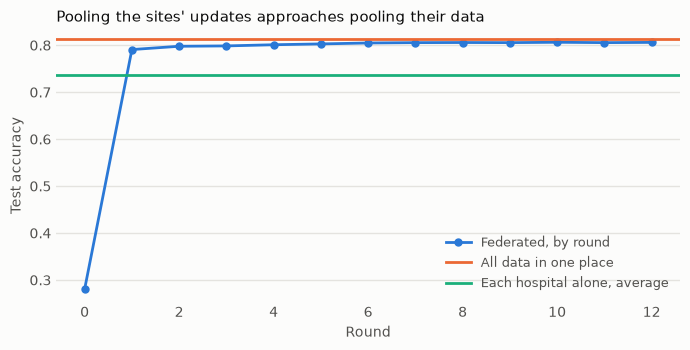

round  federated accuracy
    0  0.281
    1  0.791
    2  0.798
    3  0.798
    4  0.801
    5  0.803
    6  0.805
    7  0.805
    8  0.806
    9  0.805
   10  0.806
   11  0.805
   12  0.806


In [4]:
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

fig, ax = plt.subplots(figsize=(7, 3.6), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
rounds = np.arange(len(history))
ax.plot(rounds, history, color=BLUE, linewidth=2, marker="o", markersize=5, label="Federated, by round")
ax.axhline(accuracy(everyone), color=ORANGE, linewidth=2, label="All data in one place")
ax.axhline(np.mean(alone), color=AQUA, linewidth=2, label="Each hospital alone, average")
ax.set_xlabel("Round", color=MUTED)
ax.set_ylabel("Test accuracy", color=MUTED)
ax.set_title("Pooling the sites' updates approaches pooling their data", color=INK, loc="left", fontsize=11)
ax.tick_params(colors=MUTED, length=0)
ax.grid(axis="y", color=GRID, linewidth=1)
ax.set_axisbelow(True)
for side in ("top", "right", "left", "bottom"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, labelcolor=MUTED, loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

print("round  federated accuracy")
for r, a in zip(rounds, history):
    print(f"{r:5d}  {a:.3f}")

## What the aggregator saw

This run kept the aggregator's spool so we can look at it. Normally it's deleted when a round ends. Here's the file it received from hospital 0 in the last round, next to the update that went into it.

In [5]:
P = 2**64 - 2**32 + 1
spool = root / "masked" / "aggregator" / f"round-{ROUNDS}" / "site-0.bin"
held = np.fromfile(spool, dtype=np.uint64)

before = {k: np.array(v) for k, v in ft.load_model(root / "masked" / "site-0" / "models" / f"round-{ROUNDS - 1}.safetensors").items()}
after = fit(before, *hospitals[0])
weight = len(hospitals[0][1])
plain = np.round((after["w"] - before["w"]).astype(np.float64) * 2**24).astype(np.int64) * weight

print("coordinate   the real update (fixed point)   what the aggregator holds")
for i in range(4):
    print(f"{i:10d}   {plain[i]:29d}   {held[i]:25d}")
print()
print(f"values above half the field: {(held > P // 2).mean():.2f} (uniform noise gives about 0.5)")
print(f"largest real coordinate:     {np.abs(plain).max():,}")
print(f"field size:                  {P:,}")

coordinate   the real update (fixed point)   what the aggregator holds
         0                       178421200          506599844512520274
         1                      -478178400        10034410240993210150
         2                       573116000         7710569611520551012
         3                       127727200        14743825207777788624

values above half the field: 0.53 (uniform noise gives about 0.5)
largest real coordinate:     1,097,534,400
field size:                  18,446,744,069,414,584,321


Masking doesn't change the answer. The same training without a helper, where the aggregator does see updates, produces the same model file byte for byte.

In [6]:
plain_run = ft.LocalFederation(
    root / "plain", start, sites=4, helpers=0, rounds=ROUNDS, max_weight=10_000, purpose="cardiac risk"
).run(lambda site, r, params: (fit(params, *hospitals[site]), len(hospitals[site][1])))

masked_digest = result.sites[0]["final_digest"]
plain_digest = plain_run.sites[0]["final_digest"]
print("masked run:", masked_digest)
print("plain run: ", plain_digest)
print("identical: ", masked_digest == plain_digest)

masked run: 30f33d92125e4a9798d527e03bb05b1cf565679fe360b464a3cdcd75f1d129ee
plain run:  30f33d92125e4a9798d527e03bb05b1cf565679fe360b464a3cdcd75f1d129ee
identical:  True


## Check it

The log is the only thing an auditor needs. Nobody has to contact the aggregator or trust it. `verify` replays the log from nothing: every signature, every rule, and the sums. Each hospital runs these same rules before it acknowledges a round. It also checks the bytes it received, its helper's numbers, and one other hospital's committed vector.

In [7]:
log = Path(result.log_path)
report = ft.verify(log, result.model_path)

print(f"purpose:    {report['purpose']}")
print(f"complete:   {report['complete']}")
print(f"log size:   {log.stat().st_size:,} bytes, {report['entries']} entries")
print(f"model:      {report['model']}")
print()
print("round  sites  total weight  attested  acknowledged")
for r in report["rounds"]:
    n = len(r["included"])
    print(f"{r['round']:5d}  {n:5d}  {r['total_weight']:12d}  {n - len(r['unattested']):8d}  {n - len(r['unacked']):12d}")

purpose:    cardiac risk
complete:   True
log size:   115,906 bytes, 222 entries
model:      30f33d92125e4a9798d527e03bb05b1cf565679fe360b464a3cdcd75f1d129ee

round  sites  total weight  attested  acknowledged
    1      4          3000         4             4
    2      4          3000         4             4
    3      4          3000         4             4
    4      4          3000         4             4
    5      4          3000         4             4
    6      4          3000         4             4
    7      4          3000         4             4
    8      4          3000         4             4
    9      4          3000         4             4
   10      4          3000         4             4
   11      4          3000         4             4
   12      4          3000         4             4


Now some tampering. Each of these would go unnoticed in a plain-text audit log.

In [8]:
lines = log.read_bytes().splitlines(keepends=True)


def attempt(name, edited):
    path = root / "edited.jsonl"
    path.write_bytes(b"".join(edited))
    try:
        ft.verify(path)
        print(f"{name}\n  -> passed\n")
    except ft.VerifyFailed as e:
        print(f"{name}\n  -> {str(e)[:120]}\n")


where = next(i for i, l in enumerate(lines) if b'"kind":"contribute"' in l)
changed = list(lines)
changed[where] = changed[where].replace(b'"weight":', b'"weight":1')
attempt("Inflate a hospital's weight", changed)

attempt("Remove a hospital's contribution", lines[:where] + lines[where + 1:])

changed = list(lines)
seal = next(i for i, l in enumerate(lines) if b'"kind":"seal"' in l)
changed[seal], changed[seal - 1] = changed[seal - 1], changed[seal]
attempt("Reorder two records", changed)

try:
    other = root / "other.safetensors"
    ft.save_model(other, start)
    ft.verify(log, other)
except ft.VerifyFailed as e:
    print(f"Hand over a different model\n  -> {str(e)[:120]}")

Inflate a hospital's weight
  -> entry 6: record: bad signature from did:key:z6MkuTUrx3UjWTUogHpUfCbCJC5xvZFaGKAasZGkP1ApscEu

Remove a hospital's contribution
  -> entry 9: close does not chain to the current head

Reorder two records
  -> entry 17: seal does not chain to the current head

Hand over a different model
  -> the model file has digest 843e17ba727d682be8c0adaf9a7e8734965ab1f6836c9c4b1d2fb03ce42f8816, the log says 30f33d92125e4a9


A cut-short log is different: what's there is valid, but `complete` is false. That covers an operator who stops early. If a site in a round goes quiet, the run stops rather than carrying on without it, and the abort record names the site.

In [9]:
path = root / "short.jsonl"
path.write_bytes(b"".join(lines[: len(lines) // 2]))
short = ft.verify(path)
print("valid:", True, "| complete:", short["complete"], "| rounds seen:", len(short["rounds"]))

valid: True | complete: False | rounds seen: 6


## Who said this could happen

Each hospital's grant lists its conditions: the purpose, which helpers it trusts, and more. These hospitals agreed to cardiac risk. If a sponsor files a plan for something else, the chain fails on each hospital's own machine and nothing trains.

In [10]:
refused = ft.LocalFederation(
    root / "refused",
    start,
    sites=4,
    helpers=1,
    rounds=1,
    purpose="insurance pricing",
    granted_purpose="cardiac risk",
    join_secs=1,
).run(lambda site, r, params: (params, 1))

print("trained:", any(s["ok"] for s in refused.sites))
print(refused.sites[0]["error"][:160])

trained: False
refused: authority check failed: proof 0: policy statement 0 rejected the arguments


The same record says why each hospital took part. Here's the first one from the run above: who invoked the grant and how long the chain of authority was.

In [11]:
joined = report["joined"][0]
print("site:      ", joined["site"][:32] + "...")
print("invoked by:", joined["admission"]["invoked_by"][:32] + "...")
print("chain:     ", joined["admission"]["chain_len"], "delegation")
print("rounds with this site's data:", [r["round"] for r in report["rounds"] if any(c["site"] == joined["site"] for c in r["included"])])

site:       did:key:z6MkhBrwPvswyhzeRcaSqNVH...
invoked by: did:key:z6MkfmPRD2KLh6DeGqJUyQQ9...
chain:      1 delegation
rounds with this site's data: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


## Privacy for a whole hospital

So far the model itself could give a hospital's patients away. With a privacy target, every hospital clips its update and adds noise before masking, and the log keeps a budget that every party checks. The run stops rather than overspend.

In [12]:
private = ft.LocalFederation(
    root / "private",
    start,
    sites=4,
    helpers=1,
    rounds=5,
    privacy=ft.Privacy(epsilon=8.0, delta=1e-3, clip=1.0),
).run(train)

spent = private.report["privacy"]
print(f"accuracy with privacy:  {accuracy(private.model):.3f}")
print(f"epsilon spent:          {spent['epsilon_spent']:.2f} of {spent['epsilon_budget']:.2f}, at delta {spent['delta']}")
print(f"rho per round, masked:  {spent['rho_spent'] / 5:.3f}")
print(f"rho per round if every mask were removed later: {spent['rho_unmasked']:.3f}")

accuracy with privacy:  0.686
epsilon spent:          6.66 of 8.00, at delta 0.001
rho per round, masked:  0.277
rho per round if every mask were removed later: 1.109


Four hospitals is a hard case: the noise in the average only falls as more sites take part. The last line is what a hospital still has if the aggregator and the helper ever pooled what they hold.

## Credentials, and taking one back

A run can admit hospitals only on credentials: here an affiliation, an ethics approval, an access grant for its dataset whose data use terms allow the run's purpose, and provenance for the dataset. The data access committee takes back one hospital's grant during round 1. Its signed revocation list reaches the log, and the hospital is out from round 2.

In [13]:
gated = ft.LocalFederation(
    root / "gated", start, sites=4, helpers=1, rounds=2, credentials=True, min_cohort=2
)

def train_then_revoke(site, round_number, params):
    if site == 0 and round_number == 1:
        gated.revoke_access(3)
    return train(site, round_number, params)

checked = gated.run(train_then_revoke).report
print("admitted on:", [c["kind"] for c in checked["joined"][0]["credentials"]])
print("hospitals in each round:", [len(r["included"]) for r in checked["rounds"]])
print("why one left:", checked["revoked"][0]["reason"])
print("complete:", checked["complete"])
workdir.cleanup()

admitted on: ['AffiliationAndRole', 'EthicsApproval', 'ControlledAccessGrants', 'Provenance']
hospitals in each round: [4, 3]
why one left: ControlledAccessGrants: it has been revoked
complete: True
